In [1]:
import os, sys
from pathlib import Path
raiz = Path.cwd()
while not (raiz / "pytest.ini").exists() and raiz != raiz.parent:
    raiz = raiz.parent
sys.path.insert(0, str(raiz)); os.chdir(raiz)
import pandas as pd, numpy as np
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)

# 01 — Dados harmonizados (spec 001)

**Pergunta:** dá para medir tela e sono de forma comparável entre as bases?

Este notebook não recalcula a harmonização: ela roda pelos scripts `analise/harmonizacao/*.py`, que gravam
`analise/dados/processados/<base>.parquet` e um log com o n depois de cada filtro. Aqui se lê o resultado
e se mostra o que cada base tem.

| Base | País | Desenho | Script |
|---|---|---|---|
| PNS 2019 | Brasil | inquérito domiciliar com peso, estrato e UPA | `pns2019.py` |
| Vigitel 2024 | Brasil (27 capitais) | inquérito telefônico com peso | `vigitel2024.py` |
| Xuzhou, Pérez-Chada, Doomscrolling, Okajima | China, Argentina, Turquia, Japão | amostras de conveniência (repositórios CC BY 4.0) | `repositorios.py` |

## 1. Quantas pessoas sobram em cada filtro

Os números conferem com o inventário (`tests/test_001_contagens.py`).

In [2]:
from analise.comum.estatistica import le_csv
n = pd.read_csv("resultados/001/tabelas/n_por_base.csv", sep=";", encoding="utf-8-sig")
n

,base,etapa,n
0,pns2019,linhas no arquivo (moradores),293726
1,pns2019,morador selecionado com entrevista (M001 = 1),90846
2,pns2019,18 anos ou mais,88531
3,pns2019,salvo (após validação),88531
4,vigitel2024,edição 2024,27048
5,vigitel2024,18 anos ou mais,27048
6,vigitel2024,salvo (após validação),27048
7,xuzhou,linhas no arquivo,2317
8,xuzhou,salvo (após validação),2317
9,argentina,linhas brutas,4115


## 2. Recodificação da exposição

As faixas de horas são diferentes em cada questionário (PNS: 5 faixas; Vigitel: 7). O ponto comum é cortar em **1 h** e **3 h**:
0 = não usa ou < 1 h; 1 = 1 a < 3 h; 2 = ≥ 3 h. As tabelas abaixo são as que o código usa (`recodes.py`).

In [3]:
from analise.harmonizacao import recodes as R
pd.DataFrame({"PNS P04502 (código → faixa)": pd.Series(R.PNS_CAT), "Vigitel q59c (código → faixa)": pd.Series(R.VIG_CAT)}).rename_axis("código original")

,PNS P04502 (código → faixa),Vigitel q59c (código → faixa)
código original,,
0,NaN,0
1,0.0,0
2,1.0,1
3,1.0,1
4,2.0,2
5,2.0,2
6,0.0,2
7,NaN,2


## 3. Equivalência entre bases

`equivalente` = mesma pergunta; `aproximada` = pergunta ou faixa diferente (a comparação diz o quê);
`não comparável` = escalas diferentes, que só se comparam por métrica padronizada (spec 004).

In [4]:
eq = pd.read_csv("resultados/001/tabelas/equivalencia.csv", sep=";", encoding="utf-8-sig", index_col=0)
eq.loc[["insonia_idx", "dif_adormecer_freq", "problema_sono_freq", "latencia_min", "tela_digital_cat", "escolaridade3"]]

,pns2019,vigitel2024,xuzhou,argentina,turquia,japao
variavel,,,,,,
insonia_idx,ausente,equivalente,ausente,ausente,ausente,ausente
dif_adormecer_freq,ausente,equivalente (âncoras diferentes),ausente,ausente,ausente,ausente
problema_sono_freq,aproximada: inclui despertar e dormir demais; ...,ausente,ausente,ausente,ausente,ausente
latencia_min,ausente,ausente,ausente,equivalente,equivalente,ausente
tela_digital_cat,aproximada,aproximada,ausente,ausente,ausente,ausente
escolaridade3,"aproximada: médio incompleto = 0 (no Vigitel, ...","aproximada: 9-11 anos inclui médio incompleto,...",ausente,ausente,ausente,ausente


## 4. Distribuição da exposição e dos desfechos (com peso amostral)

In [5]:
prev = pd.read_csv("resultados/001/tabelas/prevalencias.csv", sep=";", decimal=",", encoding="utf-8-sig")
prev

,base,variavel,categoria,n,pct_sem_peso,pct_com_peso
0,pns2019,tela_digital_cat,não usa ou < 1 h,45716,51.64,45.63
1,pns2019,tela_digital_cat,1 a < 3 h,26006,29.38,32.17
2,pns2019,tela_digital_cat,≥ 3 h,16809,18.99,22.19
3,pns2019,tela_tv_cat,não usa ou < 1 h,26072,29.45,29.33
4,pns2019,tela_tv_cat,1 a < 3 h,43210,48.81,48.90
5,pns2019,tela_tv_cat,≥ 3 h,19249,21.74,21.77
6,pns2019,problema_sono_freq,sim,16491,18.63,18.64
7,vigitel2024,tela_digital_cat,não usa ou < 1 h,8874,32.83,33.47
8,vigitel2024,tela_digital_cat,1 a < 3 h,11254,41.64,39.96
9,vigitel2024,tela_digital_cat,≥ 3 h,6901,25.53,26.57


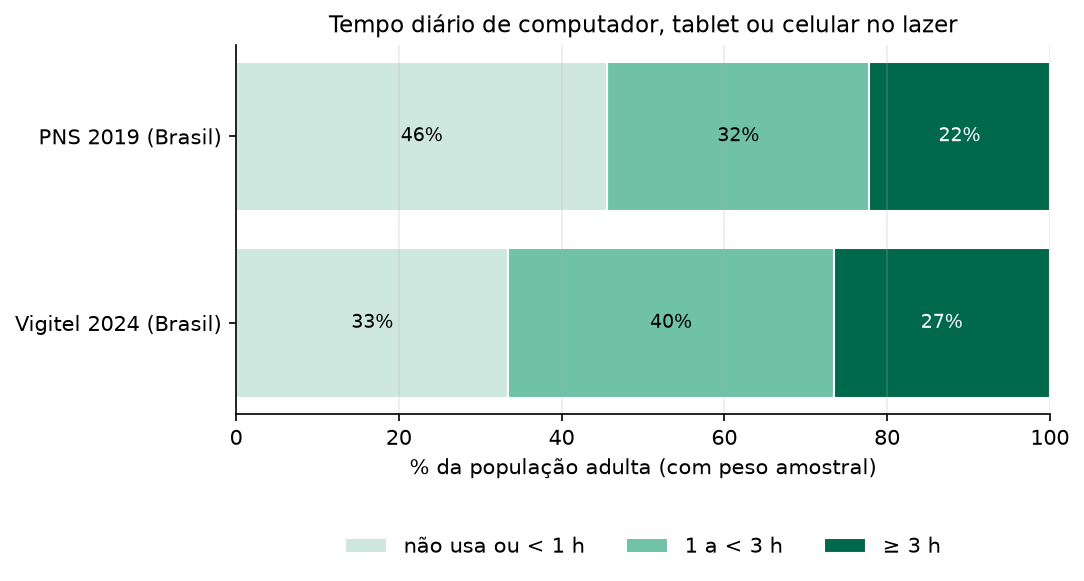

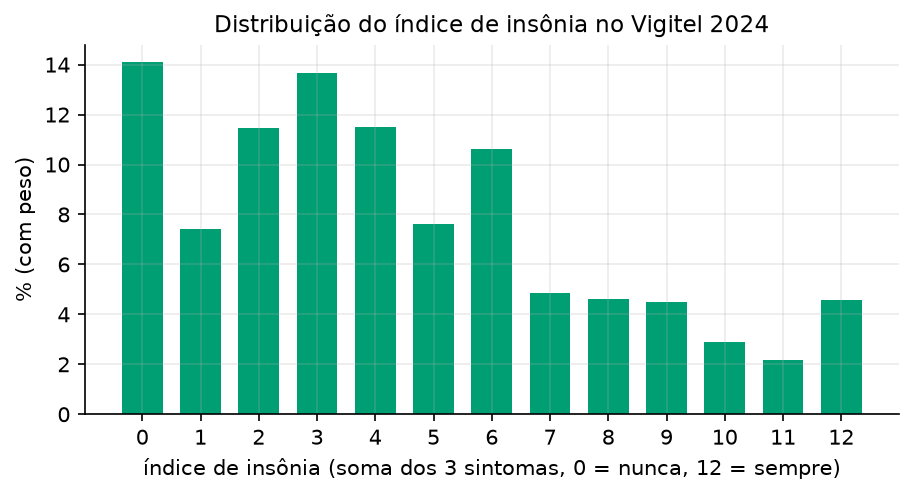

In [6]:
from IPython.display import Image, display
display(Image("resultados/001/figuras/exposicao_tela_digital.png"))
display(Image("resultados/001/figuras/indice_insonia.png"))

## 5. Leitura

- Em 2019, cerca de um em cada cinco adultos brasileiros (PNS) usava computador, tablet ou celular no lazer 3 h ou mais por dia; no Vigitel 2024 (capitais), cerca de um em cada quatro. Valores exatos na tabela acima.
- Os três sintomas de insônia do Vigitel formam o índice de insônia (0 a 12). O item de sono da PNS é o do PHQ-9 e inclui dormir demais: as duas pesquisas medem sono de forma diferente.
- Os Estados Unidos (NHANES 2005-06) foram retirados do trabalho em 2026-11-27: a base é de antes do smartphone e não ajuda nas conclusões.

Os percentuais deste texto vêm de `resultados/001/tabelas/prevalencias.csv`, impresso acima.